In [ ]:
import pathlib
import random
import re
import warnings

import alifedata_phyloinformatics_convert as apc
from hstrat import _auxiliary_lib as hstrat_aux
import iplotx as ipx
import marimo as mo
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from phyloframe import legacy as pfl
import polars as pl
from scipy import stats as scipy_stats
import seaborn as sns
from teeplot import teeplot as tp
from watermark import watermark

from pylib import osf_fetch, percentileofscore_grouped

warnings.filterwarnings("ignore", category=DeprecationWarning)

# minified phylogeny (05-minify-phylo output) of each run, by config
OSF_SLUGS = {
    "flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1": "r637f",
    "flavor=genome_mlsindiv_2026_10_18+subgrid=27+txscale=0.5+seed=2": "8er5h",
    "flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3": "pxsny",
    "flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4": "sqb9e",
}
NUM_SITES = 16
ALPHA = 0.05
NUM_CONTROL_SITES = 8
MAX_TREE_LEAVES = 4000
SEED = 1

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/alifedata_phyloinformatics_convert/_impl/phytrack_Systematcs.py:7: UserWarning: ImportWarning: phylotrackpy.Systematics import failed; inserting a no-op mock for Systematics. This is likely because phylotrackpy is not installed.
  warnings.warn(


In [ ]:
mo.md(f"""
```Text
{watermark(
    current_date=True,
    iso8601=True,
    machine=True,
    updated=True,
    python=True,
    iversions=True,
    globals_=globals(),
)}
```
""")

```Text
Last updated: 2026-10-18T23:22:05.883391+00:00

Python implementation: CPython
Python version       : 3.10.22
IPython version      : 7.31.1

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 6.17.0-1022-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit

re                                : 2.2.1
phyloframe                        : 0.12.2
iplotx                            : 1.8.0
matplotlib                        : 3.10.9
numpy                             : 2.1.2
seaborn                           : 0.13.2
pandas                            : 2.2.3
polars                            : 1.36.1
teeplot                           : 1.4.2
alifedata_phyloinformatics_convert: 0.19.3
hstrat                            : 1.25.2
marimo                            : 0.23.2
scipy                             : 1.14.1

```

In [ ]:
mo.md(f"""
# MLS Individual-host Fossils: Detectability by Population Size and Effect Size

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-18-mls-spectrum-subgrid-fossils`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-18-mls-indiv-fossils`](https://github.com/mmore500/wse-async-ga/tree/mls-indiv/wsclust/2026-10-18-mls-indiv-fossils) and are hosted on OSF, one file per run (`05-minify-phylo` output): {", ".join(f"<https://osf.io/{slug}>" for slug in OSF_SLUGS.values())}.
Within each run, each subgrid's tree was reconstructed independently.

Runs use genome flavor `genome_mlsindiv_2026_10_18`, which models individual hosts: each population member is a host, either uninfected (clear genome) or infected by the strain its genome encodes.
Eight MLS sites have effect sizes $s_i \\in [1.0, 0.5, 0.25, 0.1, 0.05, 0.025, 0.01, 0.005]$.
Each is beneficial within a host, where it is gained by within-host selection over 25 doublings with probability rising steeply with $s_i$, but harmful between hosts, blocking transmission with probability $s_i$ times `txscale` (0.5 in these runs).
The other 8 genome sites are neutral.
Runs sweep subgrid size (27, 81, 243, and 0, i.e., the full grid), where subgrids are blocks of tiles between which migration is disabled.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each MLS site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\\alpha = {ALPHA}$, broken down by population size and effect size.
As a null calibration, the same screens are applied to {NUM_CONTROL_SITES} neutral control sites.
""")

# MLS Individual-host Fossils: Detectability by Population Size and Effect Size

Applies the phylogeny-based multilevel selection (MLS) screen from *Extending a Phylogeny-based Method for Detecting Signatures of Multi-level Selection for Applications in Artificial Life* (ISAL 2025, <https://doi.org/10.1162/ISAL.a.916>; code at <https://github.com/mmore500/multilevel-selection-concept>) to wafer-scale evolution data, following `2026-10-18-mls-spectrum-subgrid-fossils`.

Data were generated by [`wse-async-ga` `wsclust/2026-10-18-mls-indiv-fossils`](https://github.com/mmore500/wse-async-ga/tree/mls-indiv/wsclust/2026-10-18-mls-indiv-fossils) and are hosted on OSF, one file per run (`05-minify-phylo` output): <https://osf.io/r637f>, <https://osf.io/8er5h>, <https://osf.io/pxsny>, <https://osf.io/sqb9e>.
Within each run, each subgrid's tree was reconstructed independently.

Runs use genome flavor `genome_mlsindiv_2026_10_18`, which models individual hosts: each population member is a host, either uninfected (clear genome) or infected by the strain its genome encodes.
Eight MLS sites have effect sizes $s_i \in [1.0, 0.5, 0.25, 0.1, 0.05, 0.025, 0.01, 0.005]$.
Each is beneficial within a host, where it is gained by within-host selection over 25 doublings with probability rising steeply with $s_i$, but harmful between hosts, blocking transmission with probability $s_i$ times `txscale` (0.5 in these runs).
The other 8 genome sites are neutral.
Runs sweep subgrid size (27, 81, 243, and 0, i.e., the full grid), where subgrids are blocks of tiles between which migration is disabled.

Each subgrid is an isolated metapopulation, so populations are analyzed independently rather than pooled: within each population, the screen asks whether each MLS site

1. gives rise to more mutation-defined clades (MDCs) than expected for a neutral site (mutation-frequency screen), and
2. gives rise to MDCs that are smaller and/or shorter-lived than neutral-site MDCs (clade-fitness screen).

Detectability is the fraction of populations in which a screen is significant at $\alpha = 0.05$, broken down by population size and effect size.
As a null calibration, the same screens are applied to 8 neutral control sites.

## Get Data

In [ ]:
data_paths = {
    config: osf_fetch(slug) for config, slug in OSF_SLUGS.items()
}

downloading https://osf.io/r637f/download -> /tmp/r637f
size: 43391819 bytes
downloading https://osf.io/8er5h/download -> /tmp/8er5h
size: 41451375 bytes
downloading https://osf.io/pxsny/download -> /tmp/pxsny
size: 42065000 bytes
downloading https://osf.io/sqb9e/download -> /tmp/sqb9e
size: 42610409 bytes


In [ ]:
pl.scan_parquet(next(iter(data_paths.values()))).collect_schema()

Schema([('origin_time', Int16), ('dstream_rank', Int16), ('dstream_S', Int16), ('hstrat_differentia_bitwidth', UInt8), ('is_extant', Boolean), ('trait_focal', UInt16), ('layer', UInt8), ('layer_T', UInt8), ('row', UInt16), ('col', UInt16), ('subgrid', UInt8), ('subgrid_row', UInt8), ('subgrid_col', UInt8), ('config', String), ('file', Categorical), ('replicate', Categorical), ('sample_per_stratum', UInt16), ('genomeFlavor', Categorical), ('populationFlavor', Categorical), ('memcpyMajor', Categorical), ('globalSeed', UInt8), ('nCol', UInt16), ('nRow', UInt16), ('nWav', UInt8), ('nTrait', UInt8), ('nCycle', UInt16), ('nColSubgrid', UInt8), ('nRowSubgrid', UInt8), ('nonBlock', Boolean), ('tilePopSize', UInt16), ('tournSize', Float32), ('msec', Float32), ('tsc', UInt8), ('dstream_algo', Categorical), ('dstream_storage_bitoffset', UInt8), ('dstream_storage_bitwidth', UInt8), ('dstream_T_bitoffset', UInt8), ('dstream_T_bitwidth', UInt8), ('dstream_S_right', UInt8), ('flag_site_bitwidth', UInt8), ('flag_sites_bitoffset', UInt8), ('flag_sites_bitwidth', UInt8), ('mls_transmission_reduction_p_byte1_bit0', Float32), ('mls_withinhost_gain_p_byte1_bit0', Float32), ('mls_withinhost_loss_p_byte1_bit0', Float32), ('mls_transmission_reduction_p_byte1_bit1', Float32), ('mls_withinhost_gain_p_byte1_bit1', Float32), ('mls_withinhost_loss_p_byte1_bit1', Float32), ('mls_transmission_reduction_p_byte1_bit2', Float32), ('mls_withinhost_gain_p_byte1_bit2', Float32), ('mls_withinhost_loss_p_byte1_bit2', Float32), ('mls_transmission_reduction_p_byte1_bit3', Float32), ('mls_withinhost_gain_p_byte1_bit3', Float32), ('mls_withinhost_loss_p_byte1_bit3', Float32), ('mls_transmission_reduction_p_byte1_bit4', Float32), ('mls_withinhost_gain_p_byte1_bit4', Float32), ('mls_withinhost_loss_p_byte1_bit4', Float32), ('mls_transmission_reduction_p_byte1_bit5', Float32), ('mls_withinhost_gain_p_byte1_bit5', Float32), ('mls_withinhost_loss_p_byte1_bit5', Float32), ('mls_transmission_reduction_p_byte1_bit6', Float32), ('mls_withinhost_gain_p_byte1_bit6', Float32), ('mls_withinhost_loss_p_byte1_bit6', Float32), ('mls_transmission_reduction_p_byte1_bit7', Float32), ('mls_withinhost_gain_p_byte1_bit7', Float32), ('mls_withinhost_loss_p_byte1_bit7', Float32), ('mls_host_clear_p', Float32), ('_compconf_dummy', UInt8), ('CEREBRASLIB_TRAITLOGGER_NUM_BITS', UInt16), ('CEREBRASLIB_NONZERO_FIT_FUDGE', Float32), ('CEREBRASLIB_POPULATION_EXTINCTION_PROBABILITY', Float32), ('CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE', Float32), ('CEREBRASLIB_MLS_WITHINHOST_DOUBLINGS', Float32), ('CEREBRASLIB_TRAITLOGGER_DILATION', UInt8), ('CEREBRASLIB_MLS_WITHINHOST_LOG10_MUTATION_RATE', Float32), ('CEREBRASLIB_TRAITLOGGER_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_HSTRAT_T_DILATION', UInt8), ('CEREBRASLIB_HSTRAT_DSTREAM_ALGO_NAME', Categorical), ('CEREBRASLIB_MLS_HOST_CLEAR_P', Float32), ('ASYNC_GA_GENOME_FLAVOR', Categorical), ('ASYNC_GA_POPULATION_FLAVOR', Categorical), ('ASYNC_GA_POPSIZE', UInt16), ('clade_size', UInt8), ('last_origin_time', Int16), ('trait_present', UInt16), ('ancestor_offset', Int16)])

In [ ]:
_lazy = pl.concat(
    [pl.scan_parquet(path) for path in data_paths.values()],
    how="diagonal_relaxed",
)
_schema = _lazy.collect_schema()
_config_cols = [
    name
    for name in _schema.names()
    if name.startswith(("ASYNC_GA_", "CEREBRASLIB_", "dstream_algo"))
    or re.match(
        r"^mls_(transmission_reduction|withinhost_(gain|loss))_p_byte\d+_bit\d+$",
        name,
    )
    or name
    in (
        "config",
        "genomeFlavor",
        "populationFlavor",
        "globalSeed",
        "nCol",
        "nRow",
        "nColSubgrid",
        "nRowSubgrid",
        "nWav",
        "nTrait",
        "nCycle",
        "tilePopSize",
        "tournSize",
        "replicate",
        "trait_focal",
        "dstream_S",
        "hstrat_differentia_bitwidth",
    )
]
config_df = (
    _lazy.filter(pl.col("clade_size") > 0)
    .select(_config_cols)
    .unique()
    .sort("nRowSubgrid")
    .collect()
)
assert config_df["config"].is_unique().all(), "expected one row per run"
assert set(config_df["config"]) == set(data_paths), "config mismatch"
assert (config_df["nRowSubgrid"] == config_df["nColSubgrid"]).all()
config_df.transpose(include_header=True)

column,column_0,column_1,column_2,column_3
str,str,str,str,str
"""dstream_S""","""128""","""128""","""128""","""128"""
"""hstrat_differentia_bitwidth""","""1""","""1""","""1""","""1"""
"""trait_focal""","""65280""","""65280""","""65280""","""65280"""
"""config""","""flavor=genome_mlsindiv_2026_10…","""flavor=genome_mlsindiv_2026_10…","""flavor=genome_mlsindiv_2026_10…","""flavor=genome_mlsindiv_2026_10…"
"""replicate""","""af0b48d3-cd76-4f22-bfb5-4484b7…","""fb185991-da87-4e7b-aa4e-4013eb…","""8e5fc4b2-f6d3-4518-b549-4e3536…","""838d8b9f-664f-4566-82b8-0483b6…"
…,…,…,…,…
"""CEREBRASLIB_HSTRAT_DSTREAM_ALG…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…","""hybrid_0_steady_1_tilted_2_alg…"
"""CEREBRASLIB_MLS_HOST_CLEAR_P""","""0.1""","""0.1""","""0.1""","""0.1"""
"""ASYNC_GA_GENOME_FLAVOR""","""genome_mlsindiv_2026_10_18""","""genome_mlsindiv_2026_10_18""","""genome_mlsindiv_2026_10_18""","""genome_mlsindiv_2026_10_18"""


In [ ]:
# MLS site i is flag byte B, bit b (trait site 8B + b); its transmission
# reduction probability is effect size s_i times txscale
# (CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE)
_site_cols = [
    (int(B) * 8 + int(b), what, col)
    for col in config_df.columns
    for what, __, B, b in re.findall(
        r"^mls_(transmission_reduction|withinhost_(gain|loss))_p_byte(\d+)_bit(\d+)$",
        col,
    )
]
effect_sizes = (
    pd.DataFrame(
        [
            {
                "config": row["config"],
                "site": site,
                f"{what}_p": row[col],
            }
            for row in config_df.iter_rows(named=True)
            for site, what, col in _site_cols
        ],
    )
    .groupby(["config", "site"], as_index=False)
    .first()
    .merge(
        config_df.select(
            "config",
            "tilePopSize",
            "CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE",
        ).to_pandas()
    )
)
effect_sizes["effect_size"] = (
    effect_sizes["transmission_reduction_p"]
    / effect_sizes["CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE"]
).round(6)
# effect sizes are the same across runs
assert (effect_sizes.groupby("site")["effect_size"].nunique() == 1).all()
focal_sites = sorted(effect_sizes["site"].unique().tolist())
_focal_mask = sum(1 << site for site in focal_sites)
assert (config_df["trait_focal"] == _focal_mask).all(), "focal mismatch"
background_sites = [
    site for site in range(NUM_SITES) if site not in focal_sites
]
control_sites = sorted(
    np.random.default_rng(SEED)
    .choice(background_sites, NUM_CONTROL_SITES, replace=False)
    .tolist()
)
site_effect_sizes = effect_sizes.groupby("site")["effect_size"].first()
effect_sizes

,config,site,transmission_reduction_p,withinhost_gain_p,withinhost_loss_p,tilePopSize,CEREBRASLIB_MLS_TRANSMISSION_REDUCTION_SCALE,effect_size
0,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,8,0.5000,0.999986,0.000002,1152,0.5,1.000
1,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,9,0.2500,0.349243,0.000003,1152,0.5,0.500
2,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,10,0.1250,0.002064,0.000005,1152,0.5,0.250
3,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,11,0.0500,0.000112,0.000010,1152,0.5,0.100
4,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,12,0.0250,0.000050,0.000015,1152,0.5,0.050
...,...,...,...,...,...,...,...,...
27,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,11,0.0500,0.000112,0.000010,1152,0.5,0.100
28,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,12,0.0250,0.000050,0.000015,1152,0.5,0.050
29,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,13,0.0125,0.000035,0.000019,1152,0.5,0.025
30,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,14,0.0050,0.000028,0.000022,1152,0.5,0.010


## Prep Data

Minification collapsed each maximal clade of genomes sharing identical traits onto its root, which became a leaf; `clade_size` gives the number of fossil genomes it represents, and `last_origin_time` the latest among them.
Genome counts below weight leaves by `clade_size`.

Fossil layer 0 samples the initial population, at `origin_time == -1` before any lineage history accumulated (as in `2026-10-15-mls-strong-fossils`), so these genomes are dropped (collapsed leaves are kept if any member has `last_origin_time >= 0`).
Some roots have no `origin_time`; as roots can be no later than the run start, it is set to -1.
Lineages without retained leaves are pruned and unifurcations collapsed.

Subgrids share no migration, so no true common ancestry links genomes from different subgrids (or runs); each run × subgrid tree was reconstructed independently.
As a safeguard, nodes whose descendant leaves span more than one population (run × subgrid) are deleted, making each maximal single-population clade a root; none are expected.
Each population's forest is then analyzed separately.

Edge subgrids are truncated by the grid boundary (e.g., 755 columns is not a multiple of 27), so only full-size subgrids are retained.

Runs are prepped one at a time, keeping only each run's final phylogeny, to limit memory use.

In [ ]:
_configs = config_df.to_pandas().set_index("config")
_phylo_parts = []
_tips_parts = []
_times_parts = []
_split_parts = []
_pop_parts = []
_num_rows = 0
for _config_code, (_config, _path) in enumerate(
    mo.status.progress_bar(list(data_paths.items())),
):
    # unminify: rows are in depth-first order, with id = row index
    _raw = (
        pl.read_parquet(
            _path,
            columns=[
                "ancestor_offset",
                "origin_time",
                "last_origin_time",
                "clade_size",
                "trait_present",
                "config",
                "layer",
                "subgrid",
            ],
        )
        .with_row_index("id")
        .with_columns(
            pl.col("id").cast(pl.Int64),
            ancestor_id=(
                pl.col("id").cast(pl.Int64)
                - pl.col("ancestor_offset").cast(pl.Int64)
            ),
            config=pl.col("config").cast(pl.String),
        )
        .drop("ancestor_offset")
        .to_pandas()
    )
    assert (_raw["config"] == _config).all()
    _is_genome = _raw["clade_size"] > 0
    assert (_is_genome == _raw["trait_present"].notna()).all()
    # trees were built partitioned by subgrid, so all rows may carry it
    assert _raw.loc[_is_genome, "subgrid"].notna().all()
    assert (_raw["ancestor_id"] <= _raw["id"]).all()
    _has_child = np.zeros(len(_raw), dtype=bool)
    _has_child[_raw["ancestor_id"]] = True
    _has_child[_raw["ancestor_id"] == _raw["id"]] = False
    # collapsed monomorphic clades and fossil genomes are leaves
    assert not (_has_child & _is_genome).any()

    # some roots lack origin_time; roots can be no later than run start
    _no_time = _raw["origin_time"].isna()
    assert (
        _raw.loc[_no_time, "ancestor_id"] == _raw.loc[_no_time, "id"]
    ).all()
    _times_parts.append(
        _raw.assign(is_genome=_is_genome)
        .groupby("is_genome")[["origin_time", "last_origin_time"]]
        .describe()
        .stack(0, future_stack=True)
        .assign(config=_config, num_missing_origin_time=_no_time.sum()),
    )
    _raw["origin_time"] = _raw["origin_time"].fillna(-1)
    _raw["last_origin_time"] = _raw["last_origin_time"].fillna(
        _raw["origin_time"]
    )
    _tips = _raw[_is_genome]
    _tips_parts.append(
        {
            "config": _config,
            "num_nodes": len(_raw),
            "num_leaves": len(_tips),
            "num_genomes": _tips["clade_size"].sum(),
            "clade_size_mean": _tips["clade_size"].mean(),
            "clade_size_max": _tips["clade_size"].max(),
            "num_layers": _tips["layer"].nunique(),
            "origin_time_min": _tips["origin_time"].min(),
            "last_origin_time_max": _tips["last_origin_time"].max(),
            "negative_origin_frac": (_tips["last_origin_time"] < 0).mean(),
        },
    )
    del _tips

    _pruned = (
        _raw.drop(columns=["layer"])
        .assign(extant=_is_genome & (_raw["last_origin_time"] >= 0))
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_prune_extinct_lineages_asexual, mutate=True)
        .pipe(pfl.alifestd_collapse_unifurcations, mutate=True)
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_mark_leaves, mutate=True)
        .reset_index(drop=True)
    )
    del _raw, _is_genome, _has_child, _no_time
    assert (_pruned["is_leaf"] == _pruned["extant"]).all()

    # split populations, deleting nodes spanning several
    _is_leaf = _pruned["is_leaf"].to_numpy()
    _pop_code = np.where(
        _is_leaf,
        _config_code * 2**32
        + _pruned["subgrid"].fillna(0).to_numpy(dtype=np.int64),
        -1,
    )
    _pure = pfl.alifestd_mask_monomorphic_clades_asexual(
        _pruned[["id", "ancestor_id"]],
        trait_mask=_is_leaf,
        trait_values=_pop_code,
    )["alifestd_mask_monomorphic_clades_asexual"].to_numpy()
    _ancestor_ids = _pruned["ancestor_id"].to_numpy()
    _is_root = _ancestor_ids == _pruned["id"].to_numpy()
    _split_parts.append(
        {
            "config": _config,
            "num_nodes": len(_pruned),
            "num_multipopulation_nodes": int((~_pure).sum()),
            "num_roots_before": int(_is_root.sum()),
            "num_roots_after": int(
                (_pure & (_is_root | ~_pure[_ancestor_ids])).sum()
            ),
        },
    )
    _split = (
        _pruned.assign(
            ancestor_id=np.where(
                _pure[_ancestor_ids], _ancestor_ids, _pruned["id"]
            ),
            pop_code=_pop_code,
        )[_pure]
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_mark_roots, mutate=True)
        .pipe(pfl.alifestd_mark_root_id, mutate=True)
        .reset_index(drop=True)
    )
    del _pruned, _is_leaf, _pop_code, _pure, _ancestor_ids, _is_root
    _root_pops = (
        _split.loc[_split["is_leaf"]]
        .groupby("root_id")["pop_code"]
        .agg(["first", "nunique"])
    )
    assert (_root_pops["nunique"] == 1).all()
    _split["pop_code"] = _split["root_id"].map(_root_pops["first"])
    assert (_split["pop_code"] >= 0).all()
    _split["subgrid"] = (_split["pop_code"] % 2**32).astype(int)

    # population geometry, to retain only full-size subgrids
    _pops = (
        _split[_split["is_leaf"]]
        .groupby("pop_code")
        .agg(
            subgrid=("subgrid", "first"),
            num_leaves=("id", "size"),
            num_genomes=("clade_size", "sum"),
            num_roots=("root_id", "nunique"),
        )
        .reset_index()
        .assign(config=_config)
    )
    # cast from shrunk dtypes (e.g., UInt8), to avoid overflow
    _cfg = {
        key: int(_configs.loc[_config, key])
        for key in ("nRow", "nCol", "nRowSubgrid", "nColSubgrid")
    }
    _nrow_sub = _cfg["nRowSubgrid"] or _cfg["nRow"]
    _ncol_sub = _cfg["nColSubgrid"] or _cfg["nCol"]
    _nsub_cols = -(-_cfg["nCol"] // _ncol_sub)
    _sub = _pops["subgrid"].to_numpy(dtype=np.int64)
    _pops["is_full_size"] = (
        (_sub // _nsub_cols + 1) * _nrow_sub <= _cfg["nRow"]
    ) & ((_sub % _nsub_cols + 1) * _ncol_sub <= _cfg["nCol"])
    _pops["pop_tiles"] = int(_nrow_sub * _ncol_sub)
    _pops["pop_size"] = f"{_nrow_sub}x{_ncol_sub}"
    _pops["tile_pop_size"] = int(_configs.loc[_config, "tilePopSize"])
    _pop_parts.append(_pops)

    _phylo = (
        _split[
            _split["pop_code"].isin(
                _pops.loc[_pops["is_full_size"], "pop_code"]
            )
        ]
        .pipe(pfl.alifestd_to_working_format, mutate=True)
        .pipe(pfl.alifestd_mark_roots, mutate=True)
        .pipe(pfl.alifestd_mark_root_id, mutate=True)
        .pipe(pfl.alifestd_mark_num_leaves_asexual, mutate=True)
        .reset_index(drop=True)
    )
    del _split, _root_pops
    _phylo["trait_present"] = (
        _phylo["trait_present"].fillna(0).to_numpy(dtype=np.uint64)
    )
    _is_leaf = _phylo["is_leaf"].to_numpy()
    _phylo["num_genomes"] = pfl.alifestd_calc_clade_trait_count_asexual(
        _phylo[["id", "ancestor_id"]],
        # passing counts rather than a mask sums genomes over descendants
        trait_mask=np.where(_is_leaf, _phylo["clade_size"], 0),
    )
    # collapsed leaves' clades last until their latest member genome
    _phylo["max_descendant_origin_time"] = (
        _phylo[["id", "ancestor_id"]]
        .assign(
            origin_time=np.where(
                _is_leaf, _phylo["last_origin_time"], _phylo["origin_time"]
            ),
        )
        .pipe(pfl.alifestd_mark_max_descendant_origin_time_asexual)[
            "max_descendant_origin_time"
        ]
        .to_numpy()
    )
    _phylo = _phylo.pipe(
        pfl.alifestd_mark_clade_duration_asexual, mutate=True
    )
    # offset ids to keep them unique and contiguous across runs
    for _col in "id", "ancestor_id", "root_id":
        _phylo[_col] += _num_rows
    _num_rows += len(_phylo)
    _phylo_parts.append(_phylo)
    del _phylo, _is_leaf

phylo = pd.concat(_phylo_parts, ignore_index=True)
del _phylo_parts
assert (phylo["id"] == phylo.index).all()
populations = pd.concat(_pop_parts, ignore_index=True)
pop_size_order = (
    populations.sort_values("pop_tiles")["pop_size"].unique().tolist()
)
tips_summary = pd.DataFrame(_tips_parts).set_index("config")
times_summary = pd.concat(_times_parts)
split_summary = pd.DataFrame(_split_parts).set_index("config")
phylo.info()

/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/phyloframe/legacy/_alifestd_try_add_ancestor_id_col.py:40: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  phylogeny_df["ancestor_id"] = phylogeny_df["ancestor_id"].astype(
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python3.10/site-packages/phyloframe/legacy/_alifestd_assign_contiguous_ids.py:79: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  phylogeny_df["id"] = np.arange(len(phylogeny_df))
/opt/hostedtoolcache/Python/3.10.22/x64/lib/python

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18607629 entries, 0 to 18607628
Data columns (total 17 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   id                          int64  
 1   origin_time                 float64
 2   last_origin_time            float64
 3   clade_size                  uint8  
 4   trait_present               uint64 
 5   config                      object 
 6   subgrid                     int64  
 7   ancestor_id                 int64  
 8   extant                      bool   
 9   is_leaf                     bool   
 10  pop_code                    int64  
 11  is_root                     bool   
 12  root_id                     int64  
 13  num_leaves                  int64  
 14  num_genomes                 int64  
 15  max_descendant_origin_time  float64
 16  clade_duration              float64
dtypes: bool(3), float64(4), int64(7), object(1), uint64(1), uint8(1)
memory usage: 1.9+ GB


In [ ]:
tips_summary.T

config,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,flavor=genome_mlsindiv_2026_10_18+subgrid=27+txscale=0.5+seed=2,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4
num_nodes,5.671496e+06,5.399621e+06,5.537810e+06,5.551985e+06
num_leaves,2.904706e+06,2.842985e+06,2.840078e+06,2.866673e+06
num_genomes,3.999967e+06,3.984288e+06,3.997350e+06,3.999900e+06
clade_size_mean,1.377064e+00,1.401445e+00,1.407479e+00,1.395311e+00
clade_size_max,3.300000e+01,2.700000e+01,3.500000e+01,3.200000e+01
num_layers,6.700000e+01,6.600000e+01,6.300000e+01,6.700000e+01
origin_time_min,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00
last_origin_time_max,7.807000e+03,7.839000e+03,7.819000e+03,7.841000e+03
negative_origin_frac,2.049467e-02,2.123402e-02,2.233953e-02,2.082344e-02


In [ ]:
times_summary

count mean std min 25% 50% 75% max config num_missing_origin_time is_genome False origin_time 2642338.0 1239.510082 1164.928428 -1.0 382.0 895.0 1662.0 7671.0 flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1 179947 last_origin_time 2642338.0 1239.510082 1164.928428 -1.0 382.0 895.0 1662.0 7671.0 flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1 179947 True origin_time 2849211.0 3280.019124 2255.710690 -1.0 1295.0 2917.0 5115.0 7803.0 flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1 179947 last_origin_time 2904706.0 3947.444797 2397.084745 -1.0 1759.0 3959.0 6133.0 7807.0 flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1 179947 False origin_time 2280332.0 1027.247608 1282.017100 -1.0 222.0 510.0 1150.0 7678.0 flavor=genome_mlsindiv_2026_10_18+subgrid=27+txscale=0.5+seed=2 429551 ... ... ... ... ... ... ... ... ... ... ... ... True last_origin_time 2840078.0 4175.829738 2316.206773 -1.0 2231.0 4273.0 6245.0 7819.0 flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3 225280 False origin_time 2515357.0 1332.453992 1418.439039 -1.0 318.0 862.0 1662.0 7703.0 flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4 254279 last_origin_time 2515357.0 1332.453992 1418.439039 -1.0 318.0 862.0 1662.0 7703.0 flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4 254279 True origin_time 2782349.0 3332.141968 2281.265891 -1.0 1291.0 3037.0 5139.0 7835.0 flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4 254279 last_origin_time 2866673.0 3961.245841 2397.275535 -1.0 1871.0 3971.0 6177.0 7841.0 flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4 254279 16 rows × 10 columns

In [ ]:
split_summary.T

config,flavor=genome_mlsindiv_2026_10_18+subgrid=0+txscale=0.5+seed=1,flavor=genome_mlsindiv_2026_10_18+subgrid=27+txscale=0.5+seed=2,flavor=genome_mlsindiv_2026_10_18+subgrid=81+txscale=0.5+seed=3,flavor=genome_mlsindiv_2026_10_18+subgrid=243+txscale=0.5+seed=4
num_nodes,5611965,5339253,5474364,5492291
num_multipopulation_nodes,0,0,0,0
num_roots_before,201796,503079,258356,288653
num_roots_after,201796,503079,258356,288653


In [ ]:
populations.groupby(["pop_size", "is_full_size"], sort=False).agg(
    num_populations=("pop_code", "size"),
    pop_tiles=("pop_tiles", "first"),
    tile_pop_size=("tile_pop_size", "first"),
    num_leaves_median=("num_leaves", "median"),
    num_genomes_median=("num_genomes", "median"),
    num_genomes_min=("num_genomes", "min"),
    num_genomes_max=("num_genomes", "max"),
    num_roots_median=("num_roots", "median"),
).T

pop_size 1170x755 27x27 81x81 243x243 is_full_size True True False True False True False num_populations 1.0 1161.0 71.0 126.0 24.0 12.0 8.0 pop_tiles 883350.0 729.0 729.0 6561.0 6561.0 59049.0 59049.0 tile_pop_size 1152.0 1152.0 1152.0 1152.0 1152.0 1152.0 1152.0 num_leaves_median 2845175.0 2260.0 2236.0 18600.0 18091.5 142244.5 135572.0 num_genomes_median 3940266.0 3185.0 3185.0 26226.0 26226.0 197010.0 197010.0 num_genomes_min 3940266.0 3185.0 3185.0 26226.0 26226.0 197010.0 197010.0 num_genomes_max 3940266.0 3185.0 3185.0 26226.0 26226.0 197010.0 197010.0 num_roots_median 201796.0 409.0 404.0 1725.0 1711.0 14513.5 14195.5

In [ ]:
_bad = ~(phylo["clade_duration"] >= 0)
phylo.loc[
    _bad,
    [
        "id",
        "ancestor_id",
        "is_leaf",
        "origin_time",
        "last_origin_time",
        "max_descendant_origin_time",
        "clade_duration",
        "clade_size",
        "pop_code",
    ],
].describe(include="all").T.assign(num_bad=int(_bad.sum()))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max,num_bad
id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
ancestor_id,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
is_leaf,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
last_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
max_descendant_origin_time,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_duration,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
clade_size,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
pop_code,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [ ]:
mo.md(f"""
## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most {MAX_TREE_LEAVES} leaves is drawn.
Diamonds mark tips carrying any MLS (focal) mutation; circles mark tips carrying any neutral (background) mutation.
""")

## Example Phylogenies

Radial tree drawings in the style of the reference work's wafer-scale figure, one per population size.
For each, a population is sampled at random and its largest tree with at most 4000 leaves is drawn.
Diamonds mark tips carrying any MLS (focal) mutation; circles mark tips carrying any neutral (background) mutation.

teeplots/2026-10-18-mls-indiv-fossils/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=10238889+viz=tree+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/edge-color=darkgray+layout=radial+pop_size=27x27+root_id=10238889+viz=tree+ext=.png


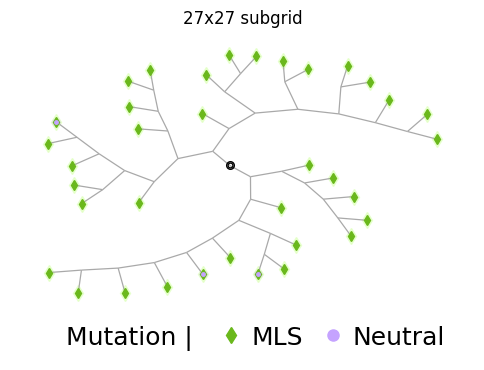

teeplots/2026-10-18-mls-indiv-fossils/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=13651469+viz=tree+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/edge-color=darkgray+layout=radial+pop_size=81x81+root_id=13651469+viz=tree+ext=.png


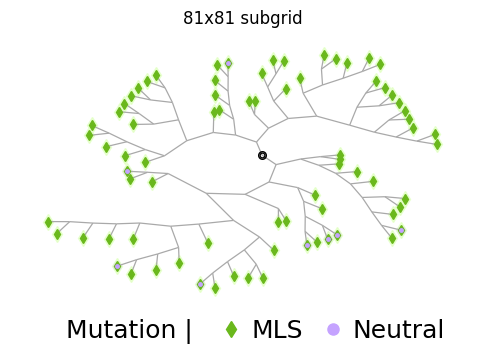

teeplots/2026-10-18-mls-indiv-fossils/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=15850468+viz=tree+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/edge-color=darkgray+layout=radial+pop_size=243x243+root_id=15850468+viz=tree+ext=.png


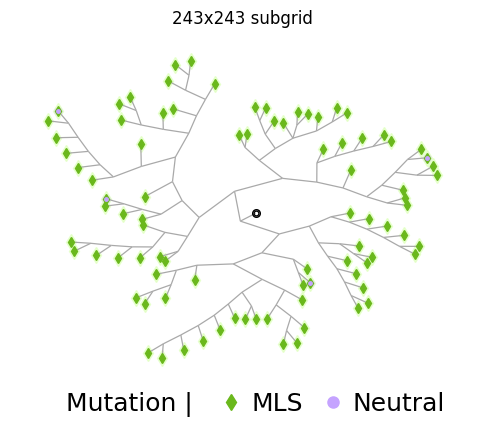

teeplots/2026-10-18-mls-indiv-fossils/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=3232232+viz=tree+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/edge-color=darkgray+layout=radial+pop_size=1170x755+root_id=3232232+viz=tree+ext=.png


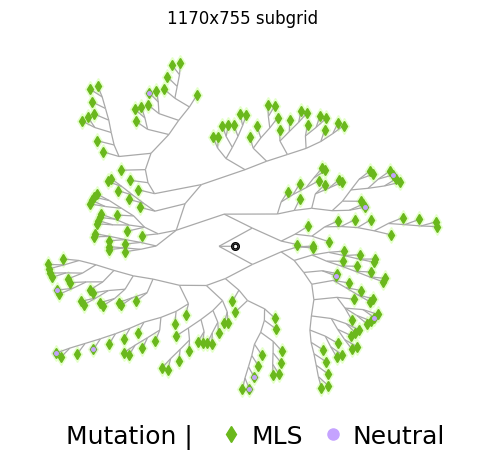

In [ ]:
_focal_mask = np.uint64(sum(1 << site for site in focal_sites))
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
_is_leaf = phylo["is_leaf"].to_numpy()
_phylo = phylo.assign(
    has_mls=np.where(
        _is_leaf, (_trait_present & _focal_mask) != 0, np.nan
    ),
    has_neutral=np.where(
        _is_leaf, (_trait_present & ~_focal_mask) != 0, np.nan
    ),
)
_roots = _phylo.loc[_phylo["is_root"], ["id", "num_leaves", "pop_code"]]
_roots = _roots[_roots["num_leaves"] <= MAX_TREE_LEAVES]
_rng = random.Random(SEED)
for _pop_size in pop_size_order:
    _pops = populations.loc[
        populations["is_full_size"]
        & (populations["pop_size"] == _pop_size)
        & populations["pop_code"].isin(_roots["pop_code"]),
        "pop_code",
    ].tolist()
    if not _pops:
        continue
    _pop_code = _rng.choice(_pops)
    _root_id = (
        _roots.loc[_roots["pop_code"] == _pop_code]
        .nlargest(1, "num_leaves")["id"]
        .item()
    )

    _subtree = (
        _phylo[_phylo["root_id"] == _root_id]
        .pipe(pfl.alifestd_assign_contiguous_ids)
        .pipe(pfl.alifestd_try_add_ancestor_list_col)
    )
    _tree = apc.alife_dataframe_to_dendropy_tree(
        _subtree,
        setattrs=["has_mls", "has_neutral"],
    )
    with hstrat_aux.RngStateContext(6):
        _tree.ladderize()
        _tree.reorder(key=lambda *args: max(random.random(), 0.89))

    with tp.teed(
        ipx.plotting.tree,
        _tree,
        aspect=0.7,
        edge_color="darkgray",
        edge_linewidth=0.9,
        ladderize=True,
        layout="radial",
        layout_angular=True,
        layout_start=0.25,
        margins=0,
        teeplot_outattrs={"pop_size": _pop_size, "root_id": _root_id},
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _teed:
        plt.gcf().set_size_inches(6, 6)

        for _n, (_x, _y) in _teed.get_layout().T.items():
            _x_, _y_ = _x * np.cos(_y), _x * np.sin(_y)
            if _n.has_mls == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=8,
                    color="#E2FFC4",
                    alpha=0.8,
                    zorder=0,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "d",
                    markersize=5,
                    color="#6AB81C",
                    alpha=1,
                    zorder=2,
                )
            if _n.has_neutral == 1.0:
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=5,
                    color="#C5A3FF",
                    alpha=0.3,
                    zorder=1,
                )
                plt.plot(
                    _x_,
                    _y_,
                    "o",
                    markersize=2.5,
                    color="#C5A3FF",
                    alpha=1.0,
                    zorder=3,
                )
            if _n is _tree.seed_node:
                for _size in 3.5, 5.5:
                    plt.plot(
                        _x_,
                        _y_,
                        "o",
                        markersize=_size,
                        color="black",
                        alpha=1,
                        fillstyle="none",
                    )

        plt.gca().margins(x=0.02, y=0.02)
        plt.title(f"{_pop_size} subgrid")

        (_h0,) = plt.plot(
            [], [], "d", markersize=0, color="#FFFFFF", label="Mutation | "
        )
        (_h1,) = plt.plot(
            [], [], "d", markersize=8, color="#6AB81C", label="MLS"
        )
        (_h2,) = plt.plot(
            [], [], "o", markersize=8, color="#C5A3FF", label="Neutral"
        )
        plt.legend(
            handles=[_h0, _h1, _h2],
            loc="upper center",
            bbox_to_anchor=(0.48, 0.05),
            frameon=False,
            ncol=4,
            fontsize=18,
            columnspacing=0.2,
            handletextpad=-0.2,
        )
    plt.close("all")

## Screen Mutation-defined Clades

MDCs are identified for each of the 64 trait sites by Fitch maximum parsimony over leaf states (root state assumed absent), as in `2026-10-15-mls-strong-fossils`.
Because each population's trees share no nodes with other populations', one screen over the whole forest is equivalent to screening each population separately.

The screen uses phyloframe's `alifestd_screen_trait_defined_clades_fitch_asexual`, which requires phyloframe >= 0.12.2 to run in linear time at this data size.

MDC size is measured as `carriers`, the number of descendant fossil genomes carrying the mutation; `num_genomes` counts all descendant fossil genomes.
`carrier_frac` is the carrier fraction among descendant genomes, and `is_terminal` marks MDCs arising on a terminal branch to a single genome (MDC node is an uncollapsed leaf).
`clade_duration` spans from MDC origin to its latest descendant fossil.

In [ ]:
_work = phylo[["id", "ancestor_id"]].copy()
_is_leaf = phylo["is_leaf"].to_numpy()
_clade_size = phylo["clade_size"].fillna(0).to_numpy(dtype=np.int64)
_trait_present = phylo["trait_present"].to_numpy(dtype=np.uint64)
mdc_ids = {}
mdc_carriers = {}
for _site in mo.status.progress_bar(range(NUM_SITES)):
    _has = ((_trait_present >> np.uint64(_site)) & np.uint64(1)) != 0
    _mask = _work.pipe(
        pfl.alifestd_screen_trait_defined_clades_fitch_asexual,
        mutate=True,
        mask_trait_absent=_is_leaf & ~_has,
        mask_trait_present=_is_leaf & _has,
    ).astype(bool)
    # passing counts rather than a mask sums carriers over descendants
    _carriers = _work.pipe(
        pfl.alifestd_calc_clade_trait_count_asexual,
        mutate=True,
        trait_mask=np.where(_is_leaf & _has, _clade_size, 0),
    )
    mdc_ids[_site] = np.flatnonzero(_mask)
    mdc_carriers[_site] = _carriers[_mask]

In [ ]:
_cols = [
    "id",
    "origin_time",
    "num_genomes",
    "clade_duration",
    "is_leaf",
    "clade_size",
    "pop_code",
]
mdcs = pd.concat(
    [
        phylo.loc[ids, _cols].assign(
            site=site,
            is_focal=site in focal_sites,
            is_control=site in control_sites,
            carriers=mdc_carriers[site],
        )
        for site, ids in mdc_ids.items()
    ],
    ignore_index=True,
)
mdcs["is_terminal"] = mdcs["is_leaf"] & (mdcs["clade_size"] == 1)
mdcs["carrier_frac"] = mdcs["carriers"] / mdcs["num_genomes"]
mdcs["effect_size"] = mdcs["site"].map(site_effect_sizes)
mdcs["mutation"] = np.where(
    mdcs["is_focal"],
    mdcs["effect_size"].map("s={:g}".format),
    "Neutral",
)
mdcs = mdcs.drop(columns=["is_leaf", "clade_size"]).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
mdcs.groupby(["pop_size", "mutation"], sort=False).agg(
    num_mdcs=("id", "size"),
    carriers_mean=("carriers", "mean"),
    carriers_singleton_frac=("carriers", lambda x: (x == 1).mean()),
    carrier_frac_mean=("carrier_frac", "mean"),
    terminal_frac=("is_terminal", "mean"),
    clade_duration_mean=("clade_duration", "mean"),
).unstack("pop_size")

num_mdcs carriers_mean carriers_singleton_frac ... carrier_frac_mean terminal_frac clade_duration_mean pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation Neutral 181116.0 167674.0 158181.0 114439.0 1.273670 1.300697 1.285249 1.222232 0.807438 0.793343 ... 0.997285 0.996879 0.807438 0.793343 0.800558 0.832076 558.830192 633.610715 606.403614 502.998348 s=0.5 1.0 1.0 NaN NaN 5.000000 2.000000 NaN NaN 0.000000 0.000000 ... NaN NaN 0.000000 0.000000 NaN NaN 6207.000000 4597.000000 NaN NaN s=0.25 509713.0 468494.0 429723.0 304915.0 1.169705 1.147449 1.161727 1.161576 0.879001 0.885281 ... 0.970890 0.970980 0.879001 0.885281 0.878526 0.879835 537.395891 536.660687 568.998087 565.867560 s=0.1 78391.0 72417.0 66907.0 47049.0 1.021265 1.021321 1.019998 1.020808 0.979513 0.979439 ... 0.996404 0.996101 0.979513 0.979439 0.980690 0.980042 73.880637 79.165831 71.383667 78.516823 s=0.05 66559.0 61883.0 57185.0 40055.0 1.033023 1.034371 1.031774 1.027612 0.968659 0.967293 ... 0.996509 0.996524 0.968659 0.967293 0.969922 0.973511 88.347646 89.433059 86.177442 81.506029 s=0.025 81057.0 76101.0 70468.0 49294.0 1.081042 1.081812 1.081058 1.065099 0.929988 0.928398 ... 0.995231 0.995113 0.929988 0.928398 0.929188 0.941494 184.986725 188.571136 190.678294 168.974236 s=0.01 106797.0 99914.0 93731.0 66149.0 1.176943 1.183978 1.180847 1.148211 0.862075 0.858098 ... 0.992770 0.992287 0.862075 0.858098 0.859513 0.878985 402.942845 429.636698 425.919312 375.365644 s=0.005 121555.0 112964.0 106039.0 75593.0 1.235005 1.250717 1.241534 1.197320 0.827535 0.818650 ... 0.992084 0.991800 0.827535 0.818650 0.822386 0.845806 528.929250 579.178783 561.410377 492.570450 8 rows × 24 columns

In [ ]:
mutation_order = [
    f"s={s:g}" for s in sorted(site_effect_sizes.unique(), reverse=True)
] + ["Neutral"]

## Mutation-frequency Screen

Within each population, baseline rate $\lambda$ is the mean MDC count per background (neutral) site.
Site significance is the Poisson survival probability of observing at least the site's MDC count under $\mathsf{Pois}(\lambda)$.
Neutral control sites are screened the same way, against the mean over the other background sites.
Populations with no background MDCs ($\lambda = 0$) are not screened.

**Caveat:** in `genome_mlsindiv_2026_10_18`, neutral sites flip at the bitwise mutation rate $2^{-18} \approx 3.8 \times 10^{-6}$ per generation, but MLS sites are gained with the within-host gain probability, which approaches $mT / (1 + mT) \approx 2.5 \times 10^{-5}$ as $s_i \to 0$ (about 6.6-fold higher).
So neutral sites are not a mutation-rate-matched baseline here, and MLS-site enrichment below largely reflects mutation supply rather than selection.

In [ ]:
_pops = populations.loc[populations["is_full_size"], "pop_code"]
_counts = (
    mdcs.groupby(["pop_code", "site"])
    .size()
    .unstack("site")
    .reindex(index=_pops, columns=range(NUM_SITES))
    .fillna(0)
)
_bg_sum = _counts[background_sites].sum(axis=1)
_num_bg = len(background_sites)
_records = []
for _site in [*focal_sites, *control_sites]:
    _is_control = _site in control_sites
    _lam = (
        (_bg_sum - _counts[_site]) / (_num_bg - 1)
        if _is_control
        else _bg_sum / _num_bg
    )
    _k = _counts[_site]
    _records.append(
        pd.DataFrame(
            {
                "pop_code": _counts.index,
                "site": _site,
                "is_control": _is_control,
                "mdc_count": _k.to_numpy(),
                "lambda": _lam.to_numpy(),
                "fold_enrichment": (_k / _lam).to_numpy(),
                "poisson_sf_p": np.where(
                    _lam > 0, scipy_stats.poisson.sf(_k - 1, _lam), np.nan
                ),
            },
        ),
    )
freq_screen = pd.concat(_records, ignore_index=True).merge(
    populations[["pop_code", "pop_size", "pop_tiles"]], on="pop_code"
)
freq_screen["mutation"] = np.where(
    freq_screen["is_control"],
    "Neutral",
    freq_screen["site"].map(site_effect_sizes).map("s={:g}".format),
)
freq_screen["detected"] = freq_screen["poisson_sf_p"] < ALPHA
freq_screen.groupby(["pop_size", "mutation"], sort=False).agg(
    num_populations=("pop_code", "nunique"),
    mdc_count_mean=("mdc_count", "mean"),
    lambda_mean=("lambda", "mean"),
    fold_enrichment_median=("fold_enrichment", "median"),
    detection_rate=("detected", "mean"),
).unstack("pop_size")

num_populations mdc_count_mean lambda_mean fold_enrichment_median detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 mutation s=1 1 1161 126 12 0.0 0.000000 0.000000 0.000000 22639.5 18.052756 156.925595 1192.072917 0.000000 0.000000 0.000000 0.000000 0.000 0.000000 0.000000 0.000000 s=0.5 1 1161 126 12 1.0 0.000861 0.000000 0.000000 22639.5 18.052756 156.925595 1192.072917 0.000044 0.000000 0.000000 0.000000 0.000 0.000000 0.000000 0.000000 s=0.25 1 1161 126 12 509713.0 403.526270 3410.500000 25409.583333 22639.5 18.052756 156.925595 1192.072917 22.514322 22.364964 21.729888 21.334976 1.000 1.000000 1.000000 1.000000 s=0.1 1 1161 126 12 78391.0 62.374677 531.007937 3920.750000 22639.5 18.052756 156.925595 1192.072917 3.462576 3.472868 3.390187 3.302630 1.000 1.000000 1.000000 1.000000 s=0.05 1 1161 126 12 66559.0 53.301464 453.849206 3337.916667 22639.5 18.052756 156.925595 1192.072917 2.939950 2.947368 2.878201 2.807801 1.000 1.000000 1.000000 1.000000 s=0.025 1 1161 126 12 81057.0 65.547804 559.269841 4107.833333 22639.5 18.052756 156.925595 1192.072917 3.580335 3.621622 3.558311 3.441335 1.000 1.000000 1.000000 1.000000 s=0.01 1 1161 126 12 106797.0 86.058570 743.896825 5512.416667 22639.5 18.052756 156.925595 1192.072917 4.717286 4.753623 4.734959 4.621172 1.000 1.000000 1.000000 1.000000 s=0.005 1 1161 126 12 121555.0 97.298880 841.579365 6299.416667 22639.5 18.052756 156.925595 1192.072917 5.369156 5.400000 5.387332 5.281159 1.000 1.000000 1.000000 1.000000 Neutral 1 1161 126 12 22639.5 18.052756 156.925595 1192.072917 22639.5 18.052756 156.925595 1192.072917 1.005002 0.992126 0.997425 1.005296 0.375 0.052433 0.073413 0.072917

teeplots/2026-10-18-mls-indiv-fossils/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/estimator=median+hue=pop-size+viz=pointplot+x=mutation+y=fold-enrichment+ext=.png


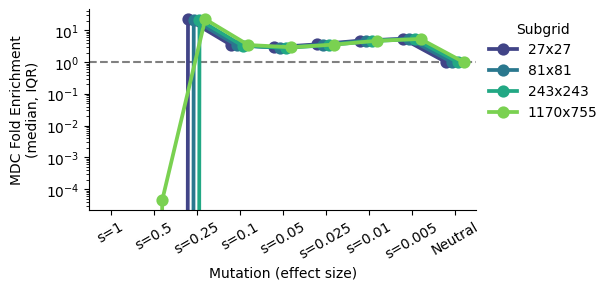

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.replace([np.inf, -np.inf], np.nan),
    x="mutation",
    y="fold_enrichment",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    _ax.axhline(1, color="gray", linestyle="--", zorder=0)
    _ax.set_yscale("log")
    _ax.set_xlabel("Mutation (effect size)")
    _ax.set_ylabel("MDC Fold Enrichment\n(median, IQR)")
    _ax.tick_params(axis="x", rotation=30)
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(5, 2.6)

teeplots/2026-10-18-mls-indiv-fossils/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/hue=pop-size+viz=pointplot+x=mutation+y=detected+ext=.png


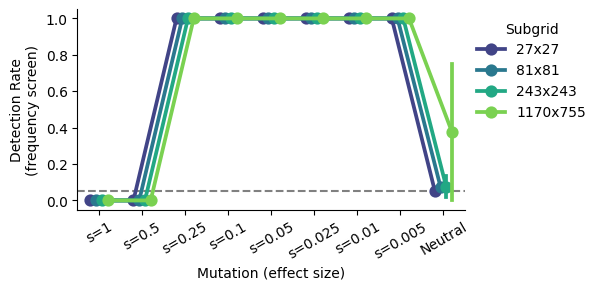

In [ ]:
with tp.teed(
    sns.pointplot,
    data=freq_screen.astype({"detected": float}),
    x="mutation",
    y="detected",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    errorbar=("ci", 95),
    n_boot=1000,
    seed=SEED,
    dodge=0.4,
    teeplot_outexclude=["palette", "hue_order", "dodge", "order", "seed"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _ax:
    _ax.axhline(ALPHA, color="gray", linestyle="--", zorder=0)
    _ax.set_ylim(-0.05, 1.05)
    _ax.set_xlabel("Mutation (effect size)")
    _ax.set_ylabel("Detection Rate\n(frequency screen)")
    _ax.tick_params(axis="x", rotation=30)
    sns.move_legend(
        _ax,
        "upper left",
        bbox_to_anchor=(1, 1),
        title="Subgrid",
        frameon=False,
    )
    sns.despine(ax=_ax)
    _ax.figure.set_size_inches(5, 2.6)

## Clade-fitness Screen

Within each population, each MDC's size (`carriers`) and clade duration are percentile-ranked (mean rank for ties) against comparator MDCs: the pooled MDCs of background (neutral) sites in the same population, drawn from the same MDC subset.
Under the `epoch100` normalization, comparison is further restricted to comparators originating within the same 100-update `origin_time` bin, controlling for recency bias.

For each population and site, a one-sided Mann-Whitney U test asks whether the site's MDC percentiles are lower than those of background MDCs (excluding the site itself, for neutral control sites).
MLS predicts lower percentiles.

MDC subsets are `all` MDCs, `inner` (excluding terminal-branch MDCs), and `inner_f75` (non-terminal MDCs with at least 75% carriers).

In [ ]:
subsets = {
    "all": lambda df: np.ones(len(df), dtype=bool),
    "inner": lambda df: ~df["is_terminal"].to_numpy(),
    "inner_f75": lambda df: (
        ~df["is_terminal"].to_numpy()
        & (df["carrier_frac"].to_numpy() >= 0.75)
    ),
}

In [ ]:
normalizations = {"all": None, "epoch100": 100}
stat_cols = ("carriers", "clade_duration")
_parts = []
for _subset, _subset_mask in subsets.items():
    _data = mdcs[_subset_mask(mdcs)]
    _comparator = ~_data["is_focal"].to_numpy()
    _keep = ~_comparator | _data["is_control"].to_numpy()
    for _norm, _binwidth in normalizations.items():
        _epoch = (
            np.zeros(len(_data), dtype=np.int64)
            if _binwidth is None
            else (_data["origin_time"].to_numpy() // _binwidth).astype(
                np.int64
            )
        )
        _groups = _data["pop_code"].to_numpy() * 2**16 + _epoch
        for _stat in stat_cols:
            _parts.append(
                _data[
                    ["pop_code", "site", "is_focal", "is_control"]
                ].assign(
                    subset=_subset,
                    normalization=_norm,
                    stat=_stat,
                    percentile=percentileofscore_grouped(
                        _data[_stat].to_numpy(dtype=float),
                        _groups,
                        _comparator,
                    ),
                ),
            )
normed = pd.concat(_parts, ignore_index=True).dropna(subset=["percentile"])

In [ ]:
_records = []
_tested_sites = [*focal_sites, *control_sites]
for (_pop, _subset, _norm, _stat), _group in mo.status.progress_bar(
    normed.groupby(
        ["pop_code", "subset", "normalization", "stat"], sort=False
    ),
):
    _sites = _group["site"].to_numpy()
    _pct = _group["percentile"].to_numpy()
    _is_bg = ~_group["is_focal"].to_numpy()
    for _site in _tested_sites:
        _in_site = _sites == _site
        _x = _pct[_in_site]
        _y = _pct[_is_bg & ~_in_site]
        if not len(_x) or not len(_y):
            continue
        _mw_u, _mw_p = scipy_stats.mannwhitneyu(_x, _y, alternative="less")
        _records.append(
            {
                "pop_code": _pop,
                "subset": _subset,
                "normalization": _norm,
                "stat": _stat,
                "site": _site,
                "n_site": len(_x),
                "n_background": len(_y),
                "site_mean_pct": _x.mean(),
                "p_mw_less": _mw_p,
                "cliffs_delta": 2 * _mw_u / (len(_x) * len(_y)) - 1,
            },
        )
fitness_screen = pd.DataFrame(_records)

In [ ]:
# one row per screened (population, site), including those with no MDCs
# in subset, which count as not detected
_pop_sites = freq_screen[["pop_code", "site", "mutation"]]
fitness_detection = (
    fitness_screen[["subset", "normalization", "stat"]]
    .drop_duplicates()
    .merge(_pop_sites, how="cross")
    .merge(
        fitness_screen,
        on=["pop_code", "site", "subset", "normalization", "stat"],
        how="left",
    )
    .merge(populations[["pop_code", "pop_size", "pop_tiles"]])
)
fitness_detection["is_control"] = fitness_detection["site"].isin(
    control_sites
)
fitness_detection["detected"] = fitness_detection["p_mw_less"] < ALPHA
fitness_detection.groupby(
    ["subset", "normalization", "stat", "pop_size", "mutation"],
    sort=False,
).agg(
    num_populations=("pop_code", "nunique"),
    num_screened=("p_mw_less", "count"),
    n_site_mean=("n_site", "mean"),
    site_mean_pct_mean=("site_mean_pct", "mean"),
    cliffs_delta_mean=("cliffs_delta", "mean"),
    detection_rate=("detected", "mean"),
).unstack(
    "pop_size"
)

num_populations num_screened n_site_mean ... site_mean_pct_mean cliffs_delta_mean detection_rate pop_size 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 ... 81x81 243x243 1170x755 27x27 81x81 243x243 1170x755 27x27 81x81 243x243 subset normalization stat mutation all all carriers s=1 1 1161 126 12 0 0 0 0 NaN NaN ... NaN NaN NaN NaN NaN NaN 0.0 0.000000 0.000000 0.000000 s=0.5 1 1161 126 12 1 1 0 0 1.000 1.000000 ... NaN NaN 0.993093 0.696970 NaN NaN 0.0 0.000000 0.000000 0.000000 s=0.25 1 1161 126 12 1 1161 126 12 509713.000 403.526270 ... 46.018342 47.606252 -0.072399 -0.094471 -0.079633 -0.047875 1.0 0.846684 1.000000 1.000000 s=0.1 1 1161 126 12 1 1161 126 12 78391.000 62.374677 ... 40.945265 42.567579 -0.173096 -0.187316 -0.181095 -0.148648 1.0 0.993109 1.000000 1.000000 s=0.05 1 1161 126 12 1 1161 126 12 66559.000 53.301464 ... 41.460223 42.881430 -0.162714 -0.175640 -0.170796 -0.142371 1.0 0.964686 1.000000 1.000000 ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... ... inner_f75 epoch100 clade_duration s=0.05 1 1161 126 12 1 465 126 12 1439.000 1.309677 ... 26.663932 30.665483 -0.408683 -0.446836 -0.470722 -0.387259 1.0 0.234281 0.698413 1.000000 s=0.025 1 1161 126 12 1 951 126 12 4654.000 2.082019 ... 32.506235 35.926674 -0.310058 -0.330225 -0.353597 -0.282172 1.0 0.372093 0.888889 1.000000 s=0.01 1 1161 126 12 1 1157 126 12 12828.000 4.963699 ... 43.343375 44.468062 -0.115654 -0.132212 -0.134927 -0.110973 1.0 0.276486 0.547619 1.000000 s=0.005 1 1161 126 12 1 1161 126 12 18456.000 7.192076 ... 46.482965 47.434304 -0.040874 -0.072790 -0.071287 -0.051418 1.0 0.198966 0.341270 0.666667 Neutral 1 1161 126 12 8 9042 1008 96 4165.125 3.754479 ... 49.978374 49.968188 -0.000014 -0.001215 -0.000446 -0.000627 0.0 0.046512 0.057540 0.041667 108 rows × 24 columns

teeplots/2026-10-18-mls-indiv-fossils/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/col=stat+estimator=median+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=site-mean-pct+ext=.png


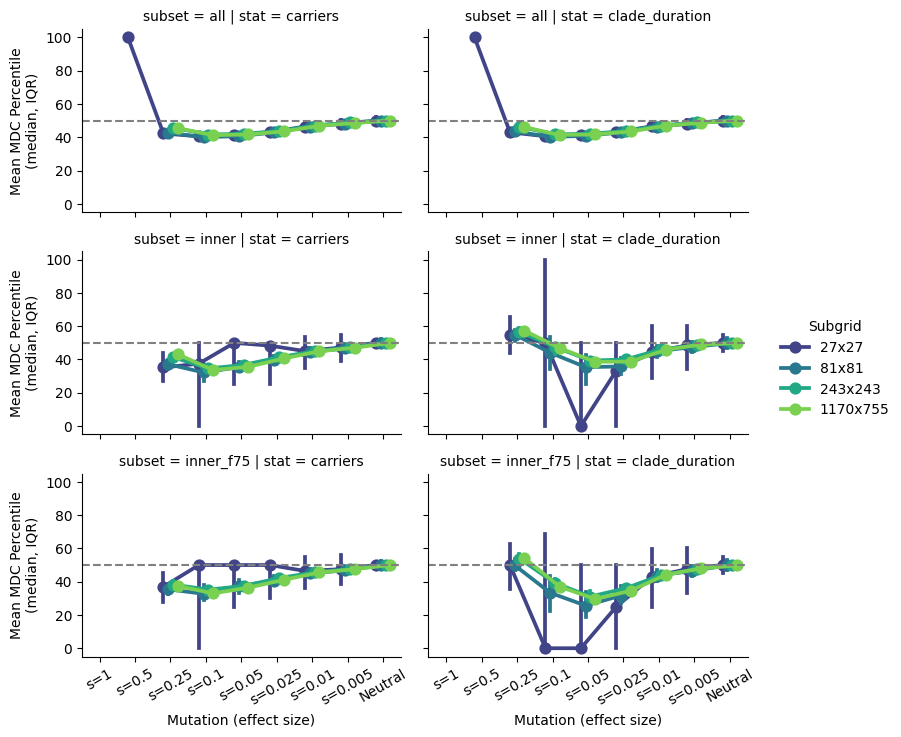

In [ ]:
with tp.teed(
    sns.catplot,
    data=fitness_detection[
        fitness_detection["normalization"] == "epoch100"
    ].dropna(subset=["site_mean_pct"]),
    x="mutation",
    y="site_mean_pct",
    order=mutation_order,
    hue="pop_size",
    hue_order=pop_size_order,
    palette="viridis",
    col="stat",
    row="subset",
    kind="point",
    estimator="median",
    errorbar=("pi", 50),
    dodge=0.4,
    height=2.4,
    aspect=1.6,
    teeplot_outattrs={"normalization": "epoch100"},
    teeplot_outexclude=["palette", "hue_order", "dodge", "order"],
    teeplot_show=True,
    teeplot_subdir=pathlib.Path(__file__).stem,
) as _g:
    _g.refline(y=50, color="gray", linestyle="--")
    _g.set_axis_labels(
        "Mutation (effect size)", "Mean MDC Percentile\n(median, IQR)"
    )
    _g.tick_params(axis="x", rotation=30)
    _g.legend.set_title("Subgrid")

teeplots/2026-10-18-mls-indiv-fossils/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/col=stat+hue=pop-size+kind=point+normalization=all+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


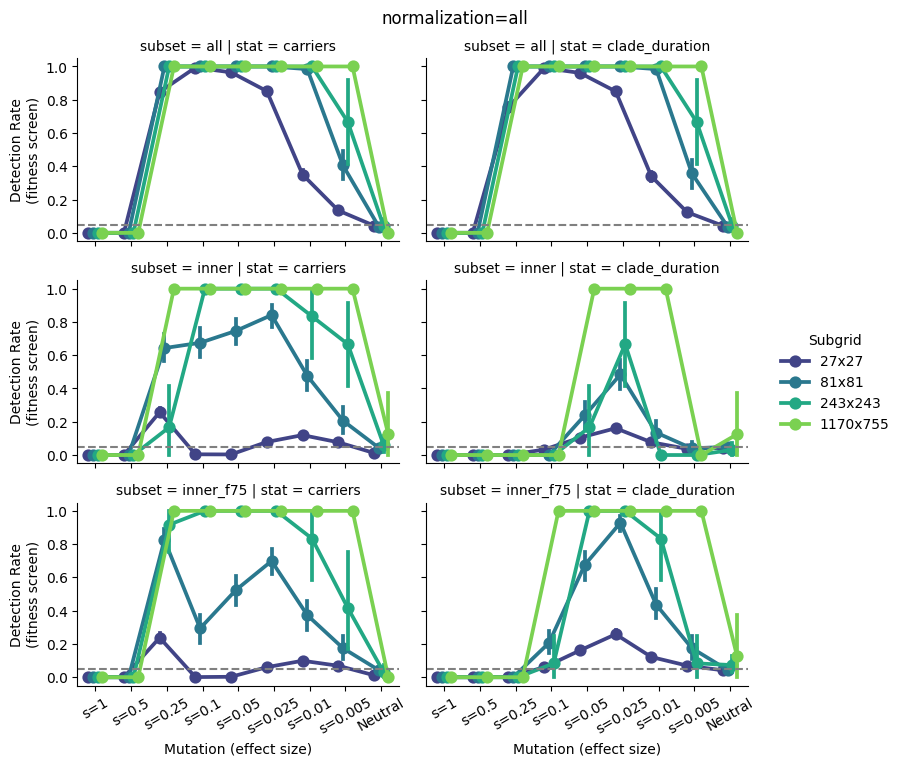

teeplots/2026-10-18-mls-indiv-fossils/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/col=stat+hue=pop-size+kind=point+normalization=epoch100+row=subset+viz=catplot+x=mutation+y=detected+ext=.png


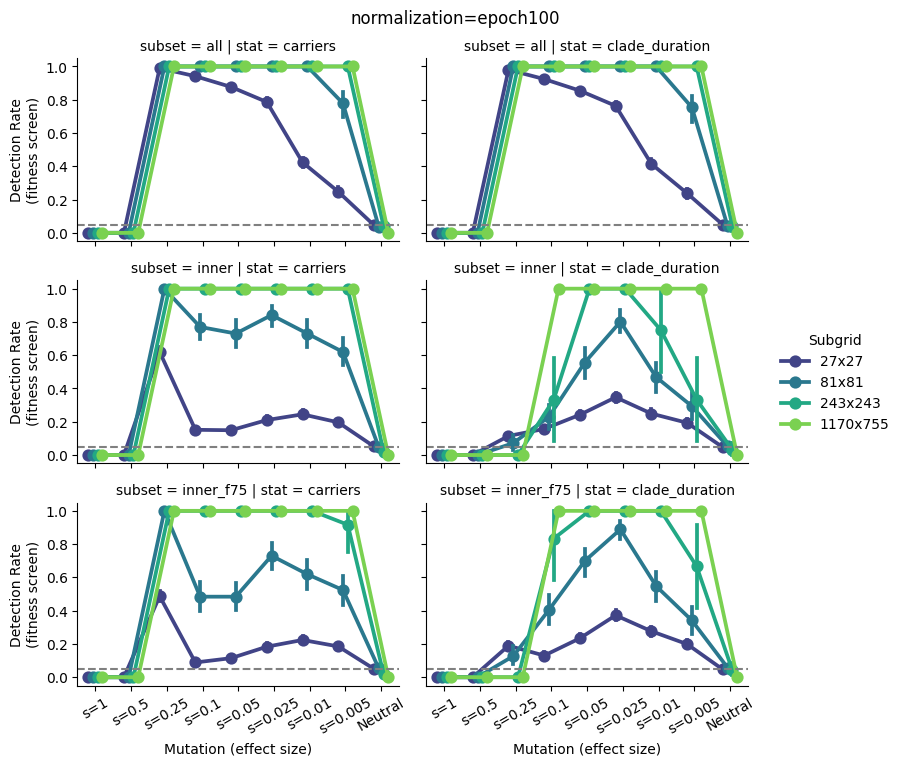

In [ ]:
for _norm in "all", "epoch100":
    with tp.teed(
        sns.catplot,
        data=fitness_detection[
            fitness_detection["normalization"] == _norm
        ].astype({"detected": float}),
        x="mutation",
        y="detected",
        order=mutation_order,
        hue="pop_size",
        hue_order=pop_size_order,
        palette="viridis",
        col="stat",
        row="subset",
        kind="point",
        errorbar=("ci", 95),
        n_boot=1000,
        seed=SEED,
        dodge=0.4,
        height=2.4,
        aspect=1.6,
        teeplot_outattrs={"normalization": _norm},
        teeplot_outexclude=[
            "palette",
            "hue_order",
            "dodge",
            "order",
            "seed",
        ],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _g:
        _g.refline(y=ALPHA, color="gray", linestyle="--")
        _g.set(ylim=(-0.05, 1.05))
        _g.set_axis_labels(
            "Mutation (effect size)", "Detection Rate\n(fitness screen)"
        )
        _g.tick_params(axis="x", rotation=30)
        _g.legend.set_title("Subgrid")
        _g.figure.suptitle(f"normalization={_norm}", y=1.02)
    plt.close("all")

In [ ]:
mo.md(f"""
## Detectability Summary

Fraction of populations in which each screen detects each site at $\\alpha = {ALPHA}$, by population size (rows) and effect size (columns).
The `Neutral` column gives the false positive rate over neutral control sites, and should sit near {ALPHA}.
Fitness screens shown use `epoch100` normalization.

The strongest MLS sites (effect sizes 1 and 0.5) are gained within-host with probability near 1 and 0.35 per generation, so they are carried from the roots of nearly all lineages; with gains at roots not counted, they give rise to almost no MDCs and cannot be screened.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per subgrid), so population size and sample size are confounded here.
""")

## Detectability Summary

Fraction of populations in which each screen detects each site at $\alpha = 0.05$, by population size (rows) and effect size (columns).
The `Neutral` column gives the false positive rate over neutral control sites, and should sit near 0.05.
Fitness screens shown use `epoch100` normalization.

The strongest MLS sites (effect sizes 1 and 0.5) are gained within-host with probability near 1 and 0.35 per generation, so they are carried from the roots of nearly all lineages; with gains at roots not counted, they give rise to almost no MDCs and cannot be screened.

Note that sampled fossil genomes per population grow with subgrid size (fossils were sampled with an equal budget per subgrid), so population size and sample size are confounded here.

In [ ]:
_screens = {
    "frequency": freq_screen,
    **{
        f"fitness {_stat} {_subset}": fitness_detection[
            (fitness_detection["normalization"] == "epoch100")
            & (fitness_detection["stat"] == _stat)
            & (fitness_detection["subset"] == _subset)
        ]
        for _stat in ("carriers", "clade_duration")
        for _subset in ("all", "inner_f75")
    },
}
detectability = pd.concat(
    [
        _df.groupby(["pop_size", "mutation"], as_index=False)
        .agg(
            detection_rate=("detected", "mean"),
            num_screened=("detected", "size"),
        )
        .assign(screen=_screen)
        for _screen, _df in _screens.items()
    ],
    ignore_index=True,
)
detectability.pivot_table(
    index=["screen", "pop_size"],
    columns="mutation",
    values="detection_rate",
    sort=False,
)

mutation Neutral s=0.005 s=0.01 s=0.025 s=0.05 s=0.1 s=0.25 s=0.5 s=1 screen pop_size frequency 1170x755 0.375000 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.0 0.0 243x243 0.072917 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.0 0.0 27x27 0.052433 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.0 0.0 81x81 0.073413 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.0 0.0 fitness carriers all 1170x755 0.000000 1.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.0 0.0 ... ... ... ... ... ... ... ... ... ... ... fitness clade_duration all 81x81 0.040675 0.753968 1.000000 1.000000 1.000000 1.000000 1.000000 0.0 0.0 fitness clade_duration inner_f75 1170x755 0.000000 1.000000 1.000000 1.000000 1.000000 1.000000 0.000000 0.0 0.0 243x243 0.041667 0.666667 1.000000 1.000000 1.000000 0.833333 0.000000 0.0 0.0 27x27 0.046512 0.198966 0.276486 0.372093 0.234281 0.130060 0.189492 0.0 0.0 81x81 0.057540 0.341270 0.547619 0.888889 0.698413 0.404762 0.126984 0.0 0.0 20 rows × 9 columns

teeplots/2026-10-18-mls-indiv-fossils/screen=frequency+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/screen=frequency+viz=heatmap+ext=.png


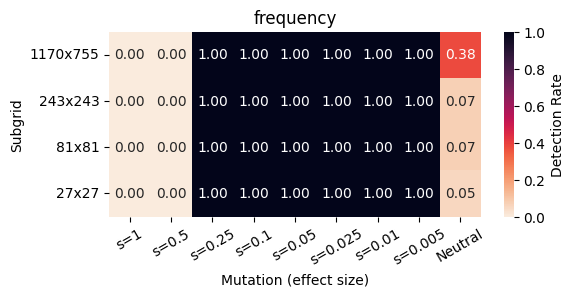

teeplots/2026-10-18-mls-indiv-fossils/screen=fitness-carriers-all+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/screen=fitness-carriers-all+viz=heatmap+ext=.png


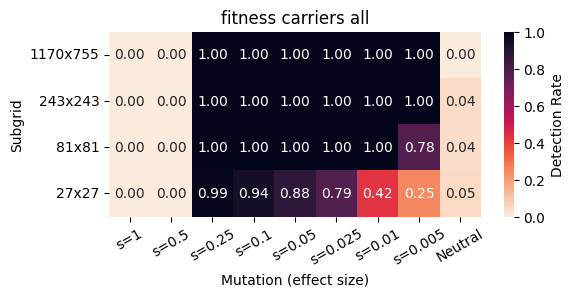

teeplots/2026-10-18-mls-indiv-fossils/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/screen=fitness-carriers-inner_f75+viz=heatmap+ext=.png


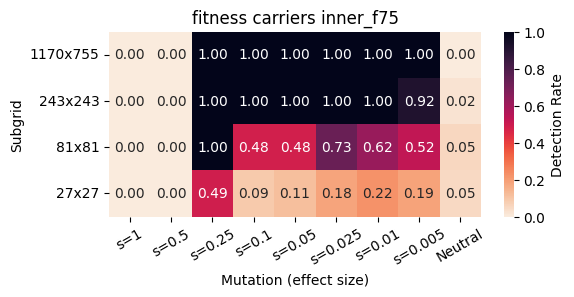

teeplots/2026-10-18-mls-indiv-fossils/screen=fitness-clade_duration-all+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/screen=fitness-clade_duration-all+viz=heatmap+ext=.png


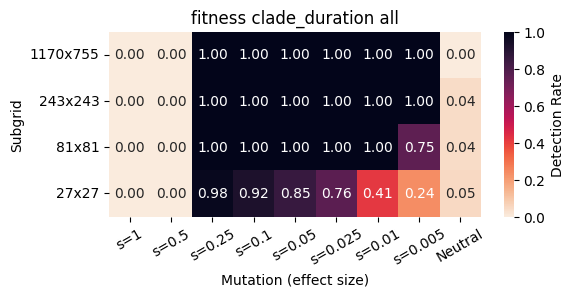

teeplots/2026-10-18-mls-indiv-fossils/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.pdf
teeplots/2026-10-18-mls-indiv-fossils/screen=fitness-clade_duration-inner_f75+viz=heatmap+ext=.png


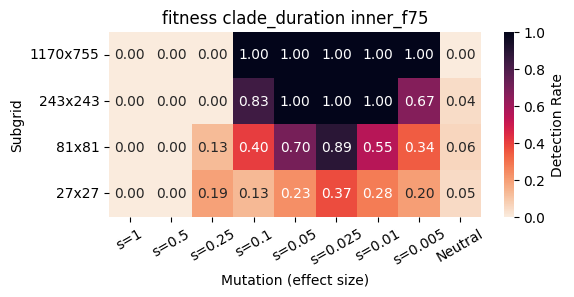

In [ ]:
for _screen, _df in detectability.groupby("screen", sort=False):
    _pivot = _df.pivot(
        index="pop_size", columns="mutation", values="detection_rate"
    ).reindex(index=pop_size_order[::-1], columns=mutation_order)
    with tp.teed(
        sns.heatmap,
        _pivot,
        annot=True,
        fmt=".2f",
        cmap="rocket_r",
        vmin=0,
        vmax=1,
        cbar_kws={"label": "Detection Rate"},
        teeplot_outattrs={"screen": _screen.replace(" ", "-")},
        teeplot_outexclude=["annot", "fmt", "cmap", "vmin", "vmax"],
        teeplot_show=True,
        teeplot_subdir=pathlib.Path(__file__).stem,
    ) as _ax:
        _ax.set_xlabel("Mutation (effect size)")
        _ax.set_ylabel("Subgrid")
        _ax.set_title(_screen)
        _ax.tick_params(axis="x", rotation=30)
        _ax.tick_params(axis="y", rotation=0)
        _ax.figure.set_size_inches(6, 2.4)
    plt.close("all")